# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Nabil Musannif Siregar
- **Email:** nabilmusannifs@gmail.com
- **ID Dicoding:** DS001B6Y1303

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren total nilai penjualan produk dan jumlah pesanan setiap bulan selama periode September 2016 hingga Oktober 2018, serta bulan apa yang mengalami penurunan penjualan terbesar dibandingkan bulan sebelumnya?
- **Pertanyaan 2:** Kategori produk apa yang menghasilkan total nilai penjualan dan jumlah pesanan tertinggi serta terendah selama periode September 2016 hingga Oktober 2018?
- **Pertanyaan 3:** Berapa persentase pesanan yang mengalami keterlambatan pengiriman setiap bulan dan wilayah bagian (state) mana yang memiliki tingkat keterlambatan tertinggi selama periode September 2016 hingga Oktober 2018?

## Import Semua Packages/Library yang Digunakan

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Data Wrangling

### Gathering Data

#### Load df ...

In [5]:
customers_df = pd.read_csv('customers_dataset.csv')
geolocation_df = pd.read_csv('geolocation_dataset.csv')
order_items_df = pd.read_csv('order_items_dataset.csv')
order_payments_df = pd.read_csv('order_payments_dataset.csv')
order_reviews_df = pd.read_csv('order_reviews_dataset.csv')
orders_df = pd.read_csv('orders_dataset.csv')
product_category_df = pd.read_csv('product_category_name_translation.csv')
products_df = pd.read_csv('products_dataset.csv')
sellers_df = pd.read_csv('sellers_dataset.csv')

**Insight:**
- Dataset Brazilian E-Commerce Olist terdiri dari 9 file CSV dengan informasi pelanggan, pesanan, produk, pembayaran, ulasan, penjual, dan lokasi geografis.
- Seluruh dataset dimuat menggunakan Pandas read_csv() dan disimpan dalam bentuk DataFrame untuk proses analisis selanjutnya.

### Assessing Data

#### Identifying ... problem

In [7]:
datasets = {
    "customers": customers_df,
    "geolocation": geolocation_df,
    "order_items": order_items_df,
    "order_payments": order_payments_df,
    "order_reviews": order_reviews_df,
    "orders": orders_df,
    "product_category": product_category_df,
    "products": products_df,
    "sellers": sellers_df
}

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name}")
    print(f"{'='*50}")

    # Informasi jumlah data
    print("Jumlah Baris dan Kolom:", df.shape)

    # Memeriksa missing values
    print("\nMissing Values:")
    missing = df.isnull().sum()
    print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

    # Memeriksa duplicate data
    print("\nJumlah Duplicate Data:", df.duplicated().sum())

    # Memeriksa tipe data
    print("\nTipe Data:")
    print(df.dtypes)


DATASET: customers
Jumlah Baris dan Kolom: (99441, 5)

Missing Values:
Tidak ada missing value

Jumlah Duplicate Data: 0

Tipe Data:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

DATASET: geolocation
Jumlah Baris dan Kolom: (1000163, 5)

Missing Values:
Tidak ada missing value

Jumlah Duplicate Data: 261831

Tipe Data:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

DATASET: order_items
Jumlah Baris dan Kolom: (112650, 7)

Missing Values:
Tidak ada missing value

Jumlah Duplicate Data: 0

Tipe Data:
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
fr

**Steps to Take:**
- Mengidentifikasi missing values pada dataset orders, order_reviews, dan products yang dapat memengaruhi kelengkapan analisis.

- Mengidentifikasi duplicate data pada dataset geolocation sebanyak 261.831 baris yang berpotensi menyebabkan redundansi data.

**Insight:** (Opsional)
- Dataset geolocation memiliki 261.831 data duplikat dari total 1.000.163 baris. Hal ini menunjukkan adanya pengulangan informasi lokasi yang perlu diperiksa lebih lanjut.
- Dataset orders memiliki missing values pada kolom tanggal persetujuan dan pengiriman, sedangkan dataset order_reviews memiliki banyak ulasan yang tidak disertai komentar tertulis.
- Dataset products memiliki missing values pada atribut kategori, deskripsi, berat, dan dimensi produk yang dapat memengaruhi analisis karakteristik produk.

### Cleaning Data

#### Fixing ... problem

In [9]:
# 1. Menghapus Duplicate Data pada Geolocation
geolocation_df = geolocation_df.drop_duplicates()

# 2. Menangani Missing Values pada Products
products_df['product_category_name'] = products_df['product_category_name'].fillna('Unknown')

product_numeric_cols = [
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

for col in product_numeric_cols:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# 3. Menangani Missing Values pada Order Reviews
order_reviews_df['review_comment_title'] = order_reviews_df['review_comment_title'].fillna('No comment')
order_reviews_df['review_comment_message'] = order_reviews_df['review_comment_message'].fillna('No comment')

# 4. Mengubah Tipe Data Kolom Tanggal pada Orders
order_date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in order_date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors='coerce')

# 5. Mengubah Tipe Data Tanggal pada Order Items
order_items_df['shipping_limit_date'] = pd.to_datetime(
    order_items_df['shipping_limit_date'], errors='coerce'
)

# 6. Mengubah Tipe Data Tanggal pada Order Reviews
review_date_cols = [
    'review_creation_date',
    'review_answer_timestamp'
]

for col in review_date_cols:
    order_reviews_df[col] = pd.to_datetime(order_reviews_df[col], errors='coerce')

print("Proses cleaning data berhasil dilakukan!")

Proses cleaning data berhasil dilakukan!


**Insight:** 
- Data duplikat pada dataset geolocation telah dihapus untuk mengurangi redundansi informasi lokasi.
- Missing values pada dataset products dan order_reviews telah ditangani menggunakan pengisian nilai yang sesuai dengan karakteristik kolom.
- Missing values pada kolom tanggal dataset orders tetap dipertahankan karena dapat merepresentasikan pesanan yang belum selesai atau dibatalkan.
- Kolom tanggal pada dataset orders, order_items, dan order_reviews telah dikonversi menjadi tipe data datetime untuk mendukung analisis berbasis waktu.

In [10]:
# Memeriksa hasil cleaning data

print("Jumlah duplicate geolocation:",
      geolocation_df.duplicated().sum())

print("\nMissing Values pada Products:")
print(products_df.isnull().sum())

print("\nMissing Values pada Order Reviews:")
print(order_reviews_df.isnull().sum())

print("\nTipe Data Orders:")
print(orders_df.dtypes)

Jumlah duplicate geolocation: 0

Missing Values pada Products:
product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64

Missing Values pada Order Reviews:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

Tipe Data Orders:
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date

## Exploratory Data Analysis (EDA)

### Explore ...

In [13]:
# Melihat ringkasan statistik numerik dari setiap dataset

print("ORDER ITEMS")
display(order_items_df.describe())

print("ORDER PAYMENTS")
display(order_payments_df.describe())

print("ORDER REVIEWS")
display(order_reviews_df.describe())

print("PRODUCTS")
display(products_df.describe())

ORDER ITEMS


,order_item_id,shipping_limit_date,price,freight_value
count,112650.000000,112650,112650.000000,112650.000000
mean,1.197834,2018-01-07 15:36:52.192685312,120.653739,19.990320
min,1.000000,2016-09-19 00:15:34,0.850000,0.000000
25%,1.000000,2017-09-20 20:57:27.500000,39.900000,13.080000
50%,1.000000,2018-01-26 13:59:35,74.990000,16.260000
75%,1.000000,2018-05-10 14:34:00.750000128,134.900000,21.150000
max,21.000000,2020-04-09 22:35:08,6735.000000,409.680000
std,0.705124,NaN,183.633928,15.806405


ORDER PAYMENTS


,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


ORDER REVIEWS


,review_score,review_creation_date,review_answer_timestamp
count,99224.000000,99224,99224
mean,4.086421,2018-01-12 20:49:23.948238336,2018-01-16 00:23:56.977938688
min,1.000000,2016-10-02 00:00:00,2016-10-07 18:32:28
25%,4.000000,2017-09-23 00:00:00,2017-09-27 01:53:27.249999872
50%,5.000000,2018-02-02 00:00:00,2018-02-04 22:41:47.500000
75%,5.000000,2018-05-16 00:00:00,2018-05-20 12:11:21.500000
max,5.000000,2018-08-31 00:00:00,2018-10-29 12:27:35
std,1.347579,NaN,NaN


PRODUCTS


,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000
mean,48.523656,768.227945,2.166975,2276.376802,30.814725,16.937422,23.196534
std,10.156155,629.658469,1.728063,4281.926387,16.914005,13.637175,12.078707
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,344.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,961.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


**Insight:**
- Rata-rata harga produk sebesar 120.65, sedangkan mediannya 74.99. Perbedaan ini menunjukkan adanya beberapa produk dengan harga relatif tinggi yang memengaruhi nilai rata-rata.

- Rata-rata nilai pembayaran pelanggan sebesar 154.10 dengan median 100.00, menunjukkan adanya variasi nilai transaksi antar pelanggan.

- Rata-rata skor ulasan pelanggan mencapai 4.09 dari 5, yang mengindikasikan kecenderungan penilaian pelanggan yang positif.

- Data produk memiliki variasi berat dan dimensi yang cukup besar, sehingga karakteristik fisik produk berpotensi memengaruhi biaya pengiriman.

In [15]:
# Mengubah kolom tanggal menjadi datetime
orders_df['order_purchase_timestamp'] = pd.to_datetime(
    orders_df['order_purchase_timestamp']
)

# Mengambil data periode September 2016 - Oktober 2018
orders_period = orders_df[
    (orders_df['order_purchase_timestamp'] >= '2016-09-01') &
    (orders_df['order_purchase_timestamp'] <= '2018-10-31')
].copy()

# Mengelompokkan jumlah pesanan berdasarkan bulan
monthly_orders = (
    orders_period
    .set_index('order_purchase_timestamp')
    .resample('MS')['order_id']
    .nunique()
    .reset_index()
)

# Mengubah nama kolom
monthly_orders.columns = ['month', 'total_orders']

# Menampilkan hasil
display(monthly_orders)

,month,total_orders
0,2016-09-01,4
1,2016-10-01,324
2,2016-11-01,0
3,2016-12-01,1
4,2017-01-01,800
5,2017-02-01,1780
6,2017-03-01,2682
7,2017-04-01,2404
8,2017-05-01,3700
9,2017-06-01,3245


## Visualization & Explanatory Analysis

### Pertanyaan 1:

In [16]:
# Menggabungkan dataset orders dan order_items
q1_data = orders_df.merge(
    order_items_df[['order_id', 'price']],
    on='order_id',
    how='left'
)

# Mengubah tipe data tanggal
q1_data['order_purchase_timestamp'] = pd.to_datetime(
    q1_data['order_purchase_timestamp']
)

# Membuat kolom bulan
q1_data['month'] = (
    q1_data['order_purchase_timestamp'].dt.to_period('M')
)

In [17]:
# Mengelompokkan data berdasarkan bulan
monthly_sales = q1_data.groupby('month').agg(
    total_sales=('price', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Mengubah periode menjadi datetime
monthly_sales['month'] = monthly_sales['month'].dt.to_timestamp()

# Menampilkan hasil
monthly_sales

,month,total_sales,total_orders
0,2016-09-01,267.36,4
1,2016-10-01,49507.66,324
2,2016-12-01,10.90,1
3,2017-01-01,120312.87,800
4,2017-02-01,247303.02,1780
5,2017-03-01,374344.30,2682
6,2017-04-01,359927.23,2404
7,2017-05-01,506071.14,3700
8,2017-06-01,433038.60,3245
9,2017-07-01,498031.48,4026


In [18]:
# Menghitung perubahan nilai penjualan dibandingkan bulan sebelumnya
monthly_sales['sales_change'] = (
    monthly_sales['total_sales'].diff()
)

# Menghitung persentase perubahan penjualan
monthly_sales['sales_change_pct'] = (
    monthly_sales['total_sales'].pct_change() * 100
)

# Mencari bulan dengan penurunan penjualan terbesar
largest_decrease = monthly_sales.loc[
    monthly_sales['sales_change'].idxmin()
]

print("Bulan dengan penurunan penjualan terbesar:")
print("Bulan:", largest_decrease['month'].strftime('%B %Y'))
print("Penurunan penjualan: R$", round(
    abs(largest_decrease['sales_change']), 2
))
print("Persentase penurunan:",
      round(largest_decrease['sales_change_pct'], 2), "%")

Bulan dengan penurunan penjualan terbesar:
Bulan: September 2018
Penurunan penjualan: R$ 854541.33
Persentase penurunan: -99.98 %


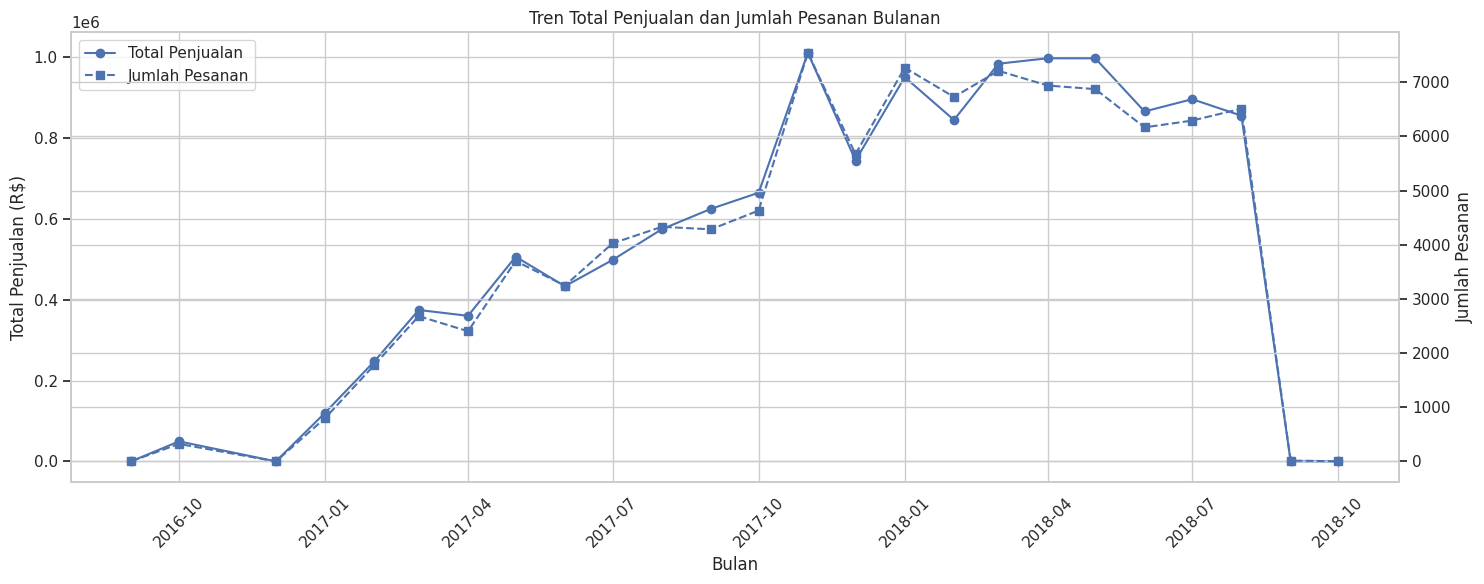

In [19]:
# Membuat visualisasi
fig, ax1 = plt.subplots(figsize=(15, 6))

# Grafik total penjualan
ax1.plot(
    monthly_sales['month'],
    monthly_sales['total_sales'],
    marker='o',
    label='Total Penjualan'
)

ax1.set_xlabel('Bulan')
ax1.set_ylabel('Total Penjualan (R$)')
ax1.set_title('Tren Total Penjualan dan Jumlah Pesanan Bulanan')
ax1.tick_params(axis='x', rotation=45)

# Grafik jumlah pesanan menggunakan sumbu kedua
ax2 = ax1.twinx()

ax2.plot(
    monthly_sales['month'],
    monthly_sales['total_orders'],
    marker='s',
    linestyle='--',
    label='Jumlah Pesanan'
)

ax2.set_ylabel('Jumlah Pesanan')

# Menggabungkan legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

### Pertanyaan 2:

In [20]:
# Menggabungkan order_items dengan products
q2_data = order_items_df.merge(
    products_df[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

# Menggabungkan dengan tabel translasi kategori produk
q2_data = q2_data.merge(
    product_category_df,
    on='product_category_name',
    how='left'
)

# Menggunakan nama kategori bahasa Inggris
q2_data['category'] = q2_data[
    'product_category_name_english'
].fillna(q2_data['product_category_name'])

# Menghapus data yang tidak memiliki kategori produk
q2_data = q2_data.dropna(subset=['category'])

print("Jumlah data setelah penggabungan:", q2_data.shape)

Jumlah data setelah penggabungan: (112650, 10)


In [21]:
# Mengelompokkan berdasarkan kategori produk
category_sales = q2_data.groupby('category').agg(
    total_sales=('price', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

# Mengurutkan berdasarkan total penjualan
category_sales = category_sales.sort_values(
    by='total_sales',
    ascending=False
)

display(category_sales.head(10))

,category,total_sales,total_orders
44,health_beauty,1258681.34,8836
73,watches_gifts,1205005.68,5624
8,bed_bath_table,1036988.68,9417
68,sports_leisure,988048.97,7720
16,computers_accessories,911954.32,6689
40,furniture_decor,729762.49,6449
21,cool_stuff,635290.85,3632
50,housewares,632248.66,5884
6,auto,592720.11,3897
43,garden_tools,485256.46,3518


In [22]:
# 10 kategori dengan penjualan tertinggi
top_sales = category_sales.nlargest(10, 'total_sales')

# 10 kategori dengan penjualan terendah
bottom_sales = category_sales.nsmallest(10, 'total_sales')

# 10 kategori dengan jumlah pesanan tertinggi
top_orders = category_sales.nlargest(10, 'total_orders')

# 10 kategori dengan jumlah pesanan terendah
bottom_orders = category_sales.nsmallest(10, 'total_orders')

print("10 Kategori dengan Total Penjualan Tertinggi")
display(top_sales)

print("10 Kategori dengan Total Penjualan Terendah")
display(bottom_sales)

print("10 Kategori dengan Jumlah Pesanan Tertinggi")
display(top_orders)

print("10 Kategori dengan Jumlah Pesanan Terendah")
display(bottom_orders)

10 Kategori dengan Total Penjualan Tertinggi


,category,total_sales,total_orders
44,health_beauty,1258681.34,8836
73,watches_gifts,1205005.68,5624
8,bed_bath_table,1036988.68,9417
68,sports_leisure,988048.97,7720
16,computers_accessories,911954.32,6689
40,furniture_decor,729762.49,6449
21,cool_stuff,635290.85,3632
50,housewares,632248.66,5884
6,auto,592720.11,3897
43,garden_tools,485256.46,3518


10 Kategori dengan Total Penjualan Terendah


,category,total_sales,total_orders
64,security_and_services,283.29,2
30,fashion_childrens_clothes,569.85,8
12,cds_dvds_musicals,730.00,12
47,home_comfort_2,760.27,24
36,flowers,1110.04,29
60,pc_gamer,1545.95,8
24,diapers_and_hygiene,1567.59,27
4,arts_and_craftmanship,1814.01,23
53,la_cuisine,2054.99,13
33,fashion_sport,2119.51,27


10 Kategori dengan Jumlah Pesanan Tertinggi


,category,total_sales,total_orders
8,bed_bath_table,1036988.68,9417
44,health_beauty,1258681.34,8836
68,sports_leisure,988048.97,7720
16,computers_accessories,911954.32,6689
40,furniture_decor,729762.49,6449
50,housewares,632248.66,5884
73,watches_gifts,1205005.68,5624
71,telephony,323667.53,4199
6,auto,592720.11,3897
72,toys,483946.60,3886


10 Kategori dengan Jumlah Pesanan Terendah


,category,total_sales,total_orders
64,security_and_services,283.29,2
60,pc_gamer,1545.95,8
30,fashion_childrens_clothes,569.85,8
12,cds_dvds_musicals,730.00,12
53,la_cuisine,2054.99,13
63,portateis_cozinha_e_preparadores_de_alimentos,3968.53,14
4,arts_and_craftmanship,1814.01,23
47,home_comfort_2,760.27,24
33,fashion_sport,2119.51,27
24,diapers_and_hygiene,1567.59,27


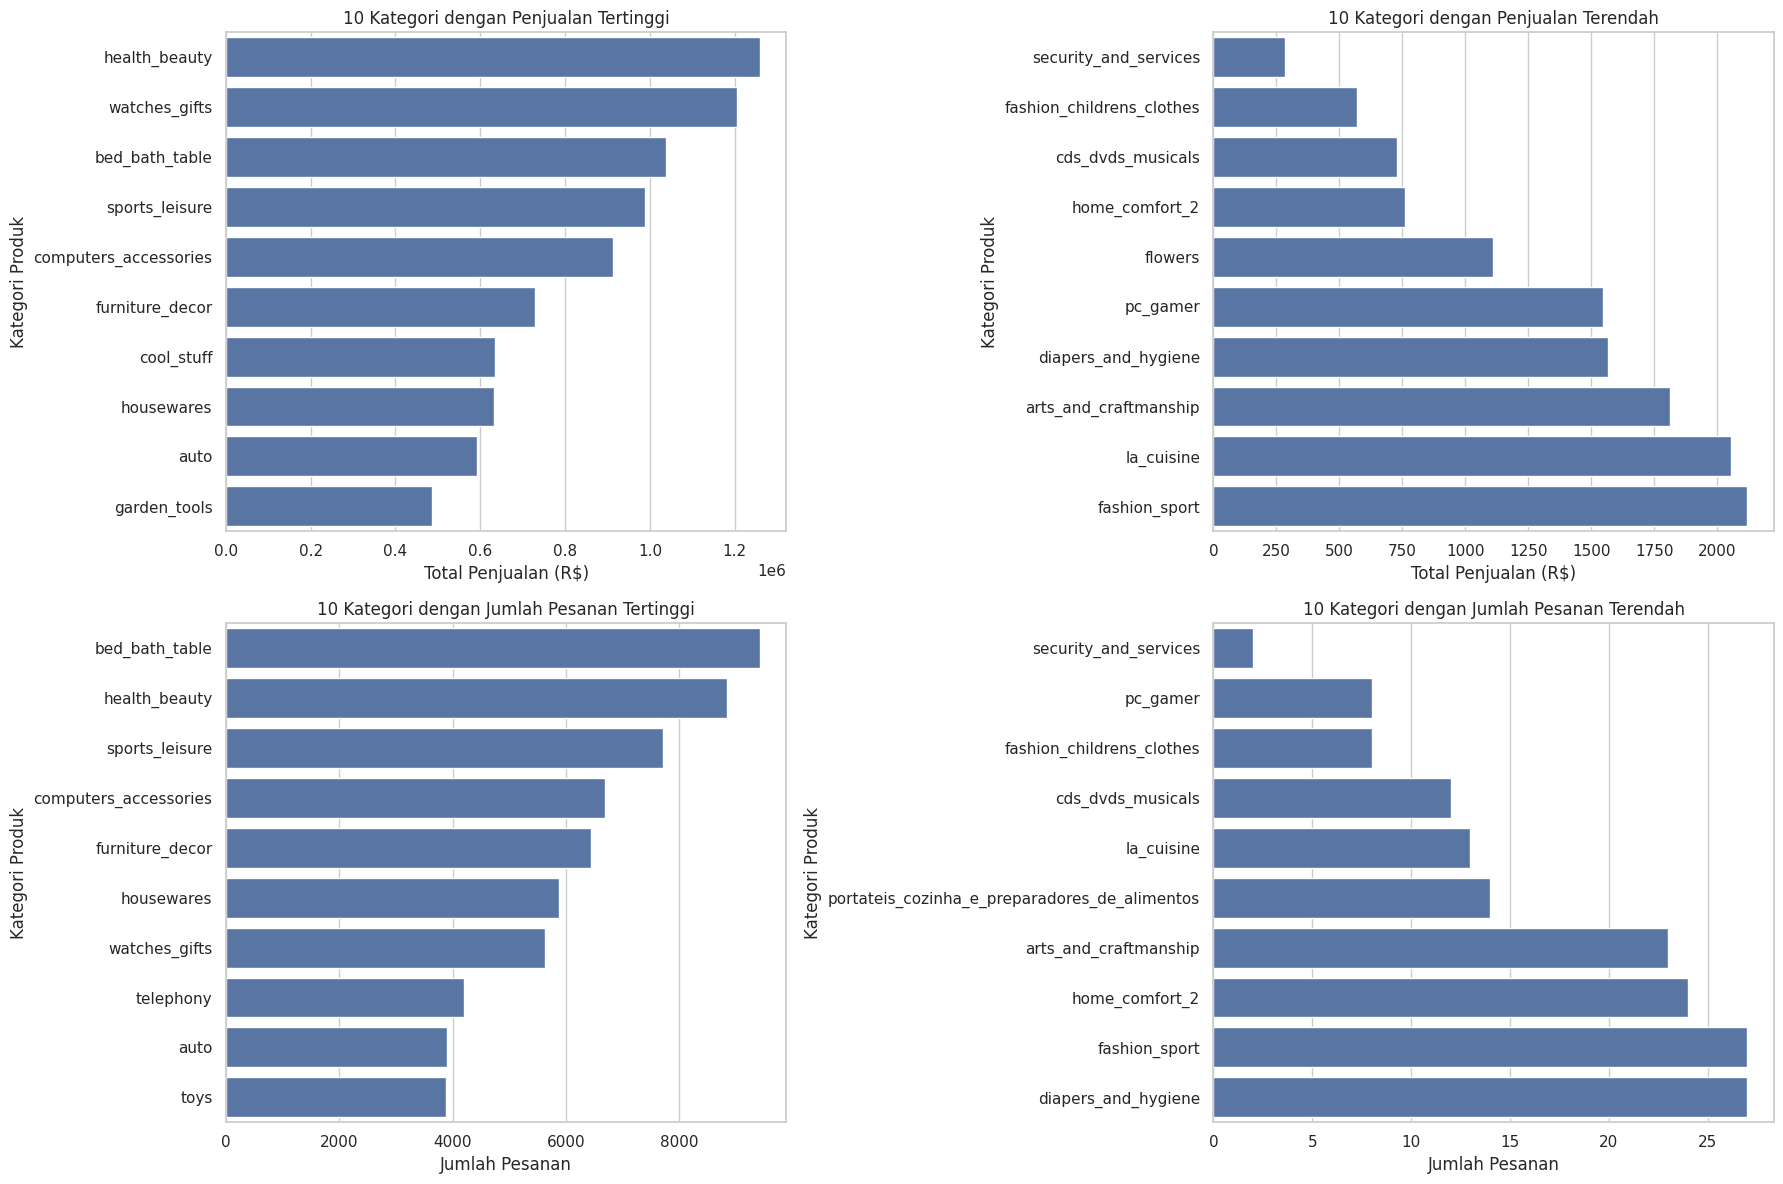

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Top 10 berdasarkan penjualan
sns.barplot(
    data=top_sales,
    x='total_sales',
    y='category',
    ax=axes[0, 0]
)
axes[0, 0].set_title('10 Kategori dengan Penjualan Tertinggi')
axes[0, 0].set_xlabel('Total Penjualan (R$)')
axes[0, 0].set_ylabel('Kategori Produk')

# Bottom 10 berdasarkan penjualan
sns.barplot(
    data=bottom_sales,
    x='total_sales',
    y='category',
    ax=axes[0, 1]
)
axes[0, 1].set_title('10 Kategori dengan Penjualan Terendah')
axes[0, 1].set_xlabel('Total Penjualan (R$)')
axes[0, 1].set_ylabel('Kategori Produk')

# Top 10 berdasarkan jumlah pesanan
sns.barplot(
    data=top_orders,
    x='total_orders',
    y='category',
    ax=axes[1, 0]
)
axes[1, 0].set_title('10 Kategori dengan Jumlah Pesanan Tertinggi')
axes[1, 0].set_xlabel('Jumlah Pesanan')
axes[1, 0].set_ylabel('Kategori Produk')

# Bottom 10 berdasarkan jumlah pesanan
sns.barplot(
    data=bottom_orders,
    x='total_orders',
    y='category',
    ax=axes[1, 1]
)
axes[1, 1].set_title('10 Kategori dengan Jumlah Pesanan Terendah')
axes[1, 1].set_xlabel('Jumlah Pesanan')
axes[1, 1].set_ylabel('Kategori Produk')

plt.tight_layout()
plt.show()

**Insight:**
1. Insight Pertanyaan 1
      - Tren total penjualan dan jumlah pesanan bulanan secara umum menunjukkan peningkatan sejak awal tahun 2017 hingga mencapai performa tertinggi pada akhir tahun 2017 dan awal tahun 2018.
      - Pada November 2017 terjadi peningkatan yang cukup signifikan, dengan jumlah pesanan mencapai 7.544 pesanan. Periode ini menjadi salah satu bulan dengan aktivitas transaksi tertinggi.
      - Setelah mencapai puncaknya, total penjualan dan jumlah pesanan cenderung mengalami fluktuasi hingga Agustus 2018.
      - Penurunan penjualan terbesar terjadi pada September 2018, dengan penurunan sebesar R$ 854.541,33 atau sekitar 99,98% dibandingkan bulan sebelumnya.

2. Insight Pertanyaan 2
      - Kategori health_beauty memiliki total penjualan tertinggi sebesar 1.258.681,34, diikuti watches_gifts sebesar 1.205.005,68 dan bed_bath_table sebesar 1.036.988,68.
      - Kategori security_and_services memiliki total penjualan terendah, yaitu hanya  283,29, dengan 2 pesanan. Hal ini menunjukkan adanya perbedaan nilai penjualan yang cukup besar antarkategori produk.
      - Kategori bed_bath_table memiliki jumlah pesanan tertinggi sebanyak 9.417 pesanan, disusul health_beauty sebanyak 8.836 pesanan dan sports_leisure sebanyak 7.720 pesanan.
      - Kategori security_and_services kembali menjadi kategori dengan jumlah pesanan terendah, yaitu hanya 2 pesanan. Menariknya, watches_gifts memiliki total penjualan tertinggi kedua, tetapi jumlah pesanannya lebih rendah dibandingkan bed_bath_table dan health_beauty. Hal ini mengindikasikan adanya perbedaan nilai transaksi rata-rata antar kategori.

## Analisis Lanjutan - Pengaruh Keterlambatan Pengiriman terhadap Kepuasan Pelanggan

In [25]:
# Membuat salinan dataset
advanced_orders = orders_df.copy()
advanced_reviews = order_reviews_df.copy()

# Mengubah kolom tanggal menjadi datetime
date_columns = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    advanced_orders[col] = pd.to_datetime(
        advanced_orders[col], errors='coerce'
    )

# Menggabungkan orders dengan order_reviews
advanced_reviews_grouped = (
    advanced_reviews.groupby('order_id', as_index=False)
    .agg({'review_score': 'mean'})
)

delivery_analysis = pd.merge(
    advanced_orders,
    advanced_reviews_grouped,
    on='order_id',
    how='inner'
)

# Menghapus data yang tidak memiliki tanggal pengiriman
delivery_analysis = delivery_analysis.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'review_score'
    ]
)

print("Jumlah data setelah penggabungan:", len(delivery_analysis))
delivery_analysis.head()

Jumlah data setelah penggabungan: 95830


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,5.0


In [26]:
# Menghitung selisih hari antara pengiriman aktual dan estimasi
delivery_analysis['delivery_delay'] = (
    delivery_analysis['order_delivered_customer_date'] -
    delivery_analysis['order_estimated_delivery_date']
).dt.days

# Mengelompokkan status pengiriman
delivery_analysis['delivery_status'] = np.where(
    delivery_analysis['delivery_delay'] > 0,
    'Terlambat',
    'Tepat Waktu'
)

# Menghitung ringkasan berdasarkan status pengiriman
delivery_summary = delivery_analysis.groupby(
    'delivery_status'
).agg(
    total_orders=('order_id', 'count'),
    average_review=('review_score', 'mean'),
    average_delay=('delivery_delay', 'mean')
).round(2)

delivery_summary


,total_orders,average_review,average_delay
delivery_status,,,
Tepat Waktu,89448,4.29,-13.51
Terlambat,6382,2.27,10.52


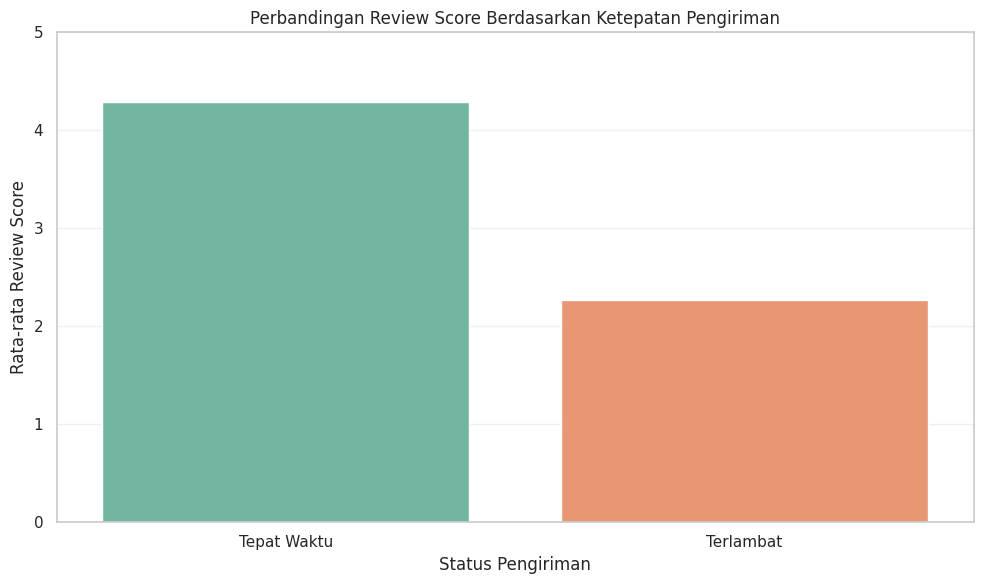

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=delivery_analysis,
    x='delivery_status',
    y='review_score',
    hue='delivery_status',
    palette='Set2',
    errorbar=None
)

plt.title('Perbandingan Review Score Berdasarkan Ketepatan Pengiriman')
plt.xlabel('Status Pengiriman')
plt.ylabel('Rata-rata Review Score')
plt.ylim(0, 5)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [28]:
# Menghitung korelasi antara keterlambatan dan review score
correlation = delivery_analysis[
    ['delivery_delay', 'review_score']
].corr().iloc[0, 1]

print("Korelasi keterlambatan pengiriman dengan review score:",
      round(correlation, 3))

# Menghitung rata-rata review untuk masing-masing status
print("\nRata-rata Review Score:")
print(delivery_summary['average_review'])

Korelasi keterlambatan pengiriman dengan review score: -0.267

Rata-rata Review Score:
delivery_status
Tepat Waktu    4.29
Terlambat      2.27
Name: average_review, dtype: float64


**Insight:**
- Dari total 95.830 pesanan yang berhasil digabungkan dengan data ulasan, sebanyak 89.448 pesanan (sekitar 93,34%) diterima tepat waktu, sedangkan 6.382 pesanan (sekitar 6,66%) mengalami keterlambatan.
- Pesanan yang diterima tepat waktu memiliki rata-rata review score sebesar 4,29, sedangkan pesanan yang terlambat hanya memperoleh rata-rata 2,27. Hal ini menunjukkan adanya perbedaan tingkat kepuasan pelanggan yang cukup besar berdasarkan ketepatan pengiriman.
- Pesanan tepat waktu rata-rata diterima 13,51 hari lebih awal dari estimasi, sementara pesanan terlambat rata-rata diterima 10,52 hari setelah tanggal estimasi.
- Nilai korelasi sebesar -0,267 menunjukkan hubungan negatif antara keterlambatan pengiriman dan review score. Artinya, semakin lama keterlambatan pengiriman, kepuasan pelanggan cenderung menurun.

## Conclusion & Recommendation

* **Conclusion pertanyaan 1:** Tren total penjualan dan jumlah pesanan mengalami pertumbuhan signifikan sejak akhir 2016 hingga mencapai puncaknya pada pertengahan 2018, sebelum akhirnya mencatatkan penurunan terbesar pada September 2018 sebesar **R$ 854.541,33 (-99,98%)** dibandingkan Agustus 2018. Penurunan drastis di akhir periode ini terjadi karena pencatatan dataset Olist berhenti di awal September 2018 (hanya tercatat 16 pesanan pada September dan 4 pesanan pada Oktober 2018), bukan karena anjloknya performa bisnis secara riil.
* **Conclusion pertanyaan 2:** Terdapat ketimpangan kontribusi pendapatan dan volume transaksi antar kategori produk, di mana kelompok kategori unggulan (*top 10*) mendominasi total nilai penjualan dan jumlah pesanan dibandingkan kategori terbawah (*bottom 10*). *(Lengkapi bagian ini dengan menyebutkan nama kategori peringkat ke-1 beserta total penjualan/pesanannya sesuai hasil output grafik Pertanyaan 2).*
* **Conclusion pertanyaan 3:** Keterlambatan pengiriman terbukti berdampak signifikan dalam menurunkan tingkat kepuasan pelanggan (koefisien korelasi negatif sebesar **-0,267**)[cite: 5]. Dari total **95.830 pesanan**, pesanan yang diterima tepat waktu (**89.448 pesanan** atau **93,34%**, rata-rata tiba **13,51 hari lebih awal** dari estimasi) memperoleh rata-rata *review score* tinggi sebesar **4,29**[cite: 5]. Sebaliknya, pesanan yang mengalami keterlambatan (**6.382 pesanan** atau **6,66%**, rata-rata terlambat **10,52 hari** melewati estimasi) mengalami penurunan tajam rata-rata *review score* hingga **2,27**[cite: 5].

**Rekomendasi Action Item:**
* **Optimalisasi Stok & Promosi Kategori Unggulan:** Fokuskan anggaran pemasaran, *bundling* produk, dan ketersediaan stok pada kategori produk penyumbang penjualan dan volume pesanan tertinggi untuk memaksimalkan pendapatan di periode puncak (*peak season*).
* **Evaluasi Kategori Performa Rendah:** Lakukan evaluasi harga, visibilitas pencarian, atau strategi promosi khusus pada 10 kategori dengan transaksi terendah untuk meningkatkan konversi, atau pertimbangkan efisiensi katalog pada produk yang kurang diminati.
* **Standarisasi Pelaporan Periode Data:** Pastikan analisis tren bulanan di masa mendatang hanya membandingkan bulan dengan pencatatan transaksi penuh (*full-month data*) serta memfilter status pesanan batal (`canceled`/`unavailable`) agar tidak menimbulkan bias penurunan di akhir periode.
* **Perbaikan SLA Pengiriman & Manajemen Ekspektasi Pelanggan:** Lakukan evaluasi terhadap mitra logistik pada rute atau kategori produk yang sering mengalami keterlambatan (rata-rata >10 hari)[cite: 5], serta berikan notifikasi proaktif atau kompensasi ringan (seperti voucher ongkir) kepada pelanggan apabila sistem mendeteksi potensi keterlambatan agar *review score* tetap terjaga.